# ۰۵ - تحلیل محصولات و عملکرد فروش

پاسخ به سؤال‌های بخش ۷ صورت‌مسئله: تعداد دسته‌بندی‌ها، رتبه‌بندی حجم و مبلغ فروش، متوسط قیمت و سهم دسته‌بندی‌ها.

## ۲. سؤال‌های کسب‌وکاری

1. چند دسته‌بندی محصول وجود دارد؟
2. ده دسته‌بندی برتر بر اساس تعداد اقلام کدام‌اند؟
3. ده دسته‌بندی برتر بر اساس مبلغ فروش کدام‌اند؟
4. آیا رتبه‌بندی حجم و مبلغ یکسان است؟
5. سهم پنج دسته‌بندی اول از کل مبلغ فروش چقدر است؟

## ۱. عنوان و هدف

پاسخ به سؤال‌های بخش ۷ صورت‌مسئله: تعداد دسته‌بندی‌ها، رتبه‌بندی حجم و مبلغ فروش، متوسط قیمت و سهم دسته‌بندی‌ها.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from olist_analysis import metrics as M
from olist_analysis.config import FIGURES_DIR, REPORTS_DIR, TABLES_DIR
from olist_analysis.font_utils import persian_available
from olist_analysis.features import load_dataset
from olist_analysis.pipeline import load_headline

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

ds = load_dataset()
headline = load_headline()
print("Persian font registered for charts:", persian_available())
print(f"orders={len(ds.orders):,}  items={len(ds.items):,}  "
      f"delivered={len(ds.delivered):,}  reviewed={len(ds.reviews_per_order):,}")


Persian font registered for charts: True
orders=99,441  items=112,650  delivered=96,470  reviewed=98,673


## ۴. روش محاسبه

مبلغ فروش اقلام از ستون `price` جدول اقلام سفارش محاسبه می‌شود. در این دیتاست هر سطر یک واحد کالا است، بنابراین مبلغ فروش هر سطر برابر همان `price` است. هزینه ارسال جداگانه گزارش می‌شود و در مبلغ فروش دسته‌بندی لحاظ نشده است.

## ۶. تحلیل عددی

### ۷.۱ ده دسته‌بندی برتر بر اساس تعداد

In [2]:
display(M.top_categories(ds, "items", 10)[["category_label", "n_items", "revenue", "rank_items", "rank_revenue"]])

,category_label,n_items,revenue,rank_items,rank_revenue
0,bed_bath_table,11115,1036988.68,1,3
1,health_beauty,9670,1258681.34,2,1
2,sports_leisure,8641,988048.97,3,4
3,furniture_decor,8334,729762.49,4,6
4,computers_accessories,7827,911954.32,5,5
5,housewares,6964,632248.66,6,8
6,watches_gifts,5991,1205005.68,7,2
7,telephony,4545,323667.53,8,14
8,garden_tools,4347,485256.46,9,10
9,auto,4235,592720.11,10,9


### ۷.۲ ده دسته‌بندی برتر بر اساس مبلغ فروش

In [3]:
display(M.top_categories(ds, "revenue", 10)[["category_label", "n_items", "revenue", "pct_revenue", "mean_item_price"]])

,category_label,n_items,revenue,pct_revenue,mean_item_price
0,health_beauty,9670,1258681.34,9.2607,130.16
1,watches_gifts,5991,1205005.68,8.8658,201.14
2,bed_bath_table,11115,1036988.68,7.6296,93.30
3,sports_leisure,8641,988048.97,7.2695,114.34
4,computers_accessories,7827,911954.32,6.7097,116.51
5,furniture_decor,8334,729762.49,5.3692,87.56
6,cool_stuff,3796,635290.85,4.6741,167.36
7,housewares,6964,632248.66,4.6517,90.79
8,auto,4235,592720.11,4.3609,139.96
9,garden_tools,4347,485256.46,3.5703,111.63


### ۷.۳ مقایسه رتبه‌بندی حجم و مبلغ

In [4]:
display(M.category_rank_comparison(ds, k=20, min_gap=5))

,category_label,n_items,revenue,mean_item_price,rank_items,rank_revenue,rank_gap_revenue_minus_items
0,computers,203,222963.13,1098.34,46,17,-29
1,telephony,4545,323667.53,71.21,8,14,6
2,electronics,2767,160246.74,57.91,15,21,6
3,fashion_bags_accessories,2031,152823.54,75.25,17,23,6
4,watches_gifts,5991,1205005.68,201.14,7,2,-5
5,cool_stuff,3796,635290.85,167.36,12,7,-5
6,small_appliances,679,190648.58,280.78,25,20,-5
7,musical_instruments,680,191498.88,281.62,24,19,-5


### ۷.۴ پنج دسته‌بندی با بالاترین متوسط قیمت (با حجم کافی)

In [5]:
display(M.top_categories(ds, "mean_price", 5))

,category_label,n_items,n_orders,revenue,mean_item_price,median_item_price,mean_freight,pct_items,pct_revenue,revenue_per_item,rank_items,rank_revenue,rank_gap_revenue_minus_items,cum_revenue_pct
0,computers,203,181,222963.13,1098.34,1100.00,48.45,0.1802,1.6404,1098.34,47,17,-30,76.2852
1,small_appliances_home_oven_and_coffee,76,75,47445.71,624.29,587.00,36.16,0.0675,0.3491,624.29,56,36,-20,99.9514
2,home_appliances_2,238,234,113317.74,476.12,225.94,44.54,0.2113,0.8337,476.12,43,27,-16,98.5092
3,agro_industry_and_commerce,212,182,72530.47,342.12,258.65,27.56,0.1882,0.5336,342.12,45,30,-15,9.2607
4,musical_instruments,680,628,191498.88,281.62,94.84,27.41,0.6036,1.4089,281.62,25,19,-6,99.6699


### ۷.۵ سهم پنج دسته‌بندی اول از کل مبلغ فروش

In [6]:
display(pd.Series(M.top_n_revenue_share(ds, 5), name="value"))

n                          5.000000e+00
total_revenue              1.341211e+07
top_n_revenue              5.400679e+06
top_n_revenue_share_pct    4.026720e+01
n_categories               7.300000e+01
Name: value, dtype: float64

## ۷. نمودارها

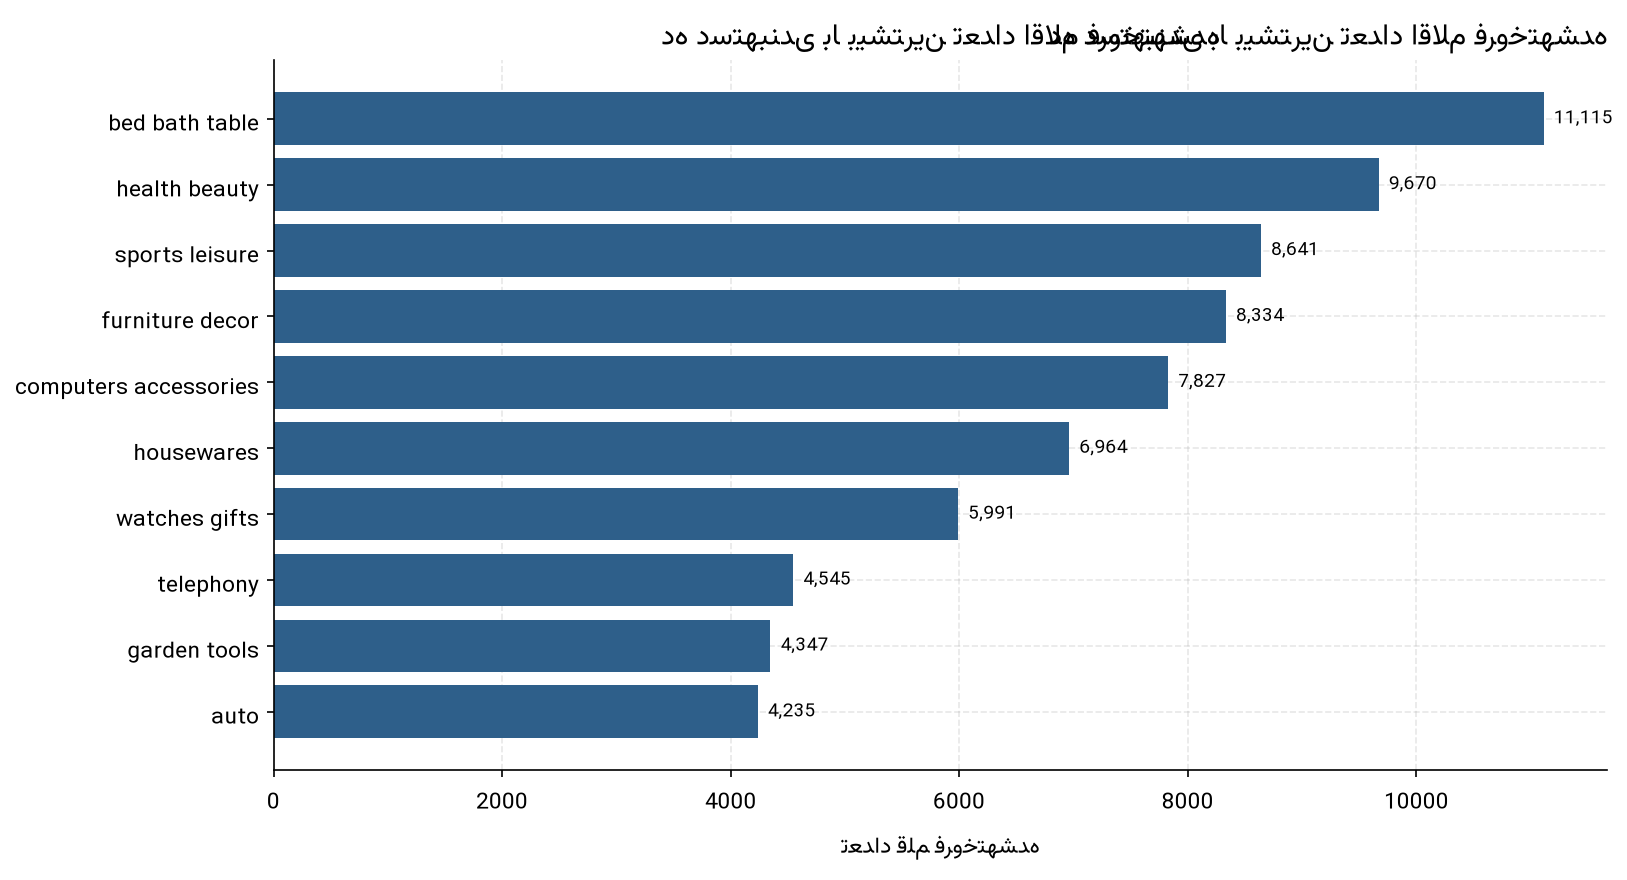

ده دستهبندی با بیشترین تعداد اقلام فروختهشده


In [7]:
display(Image(filename=str(FIGURES_DIR / "fig_08_top_categories_items.png"), width=920))
caption = FIGURES_DIR / "fig_08_top_categories_items.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

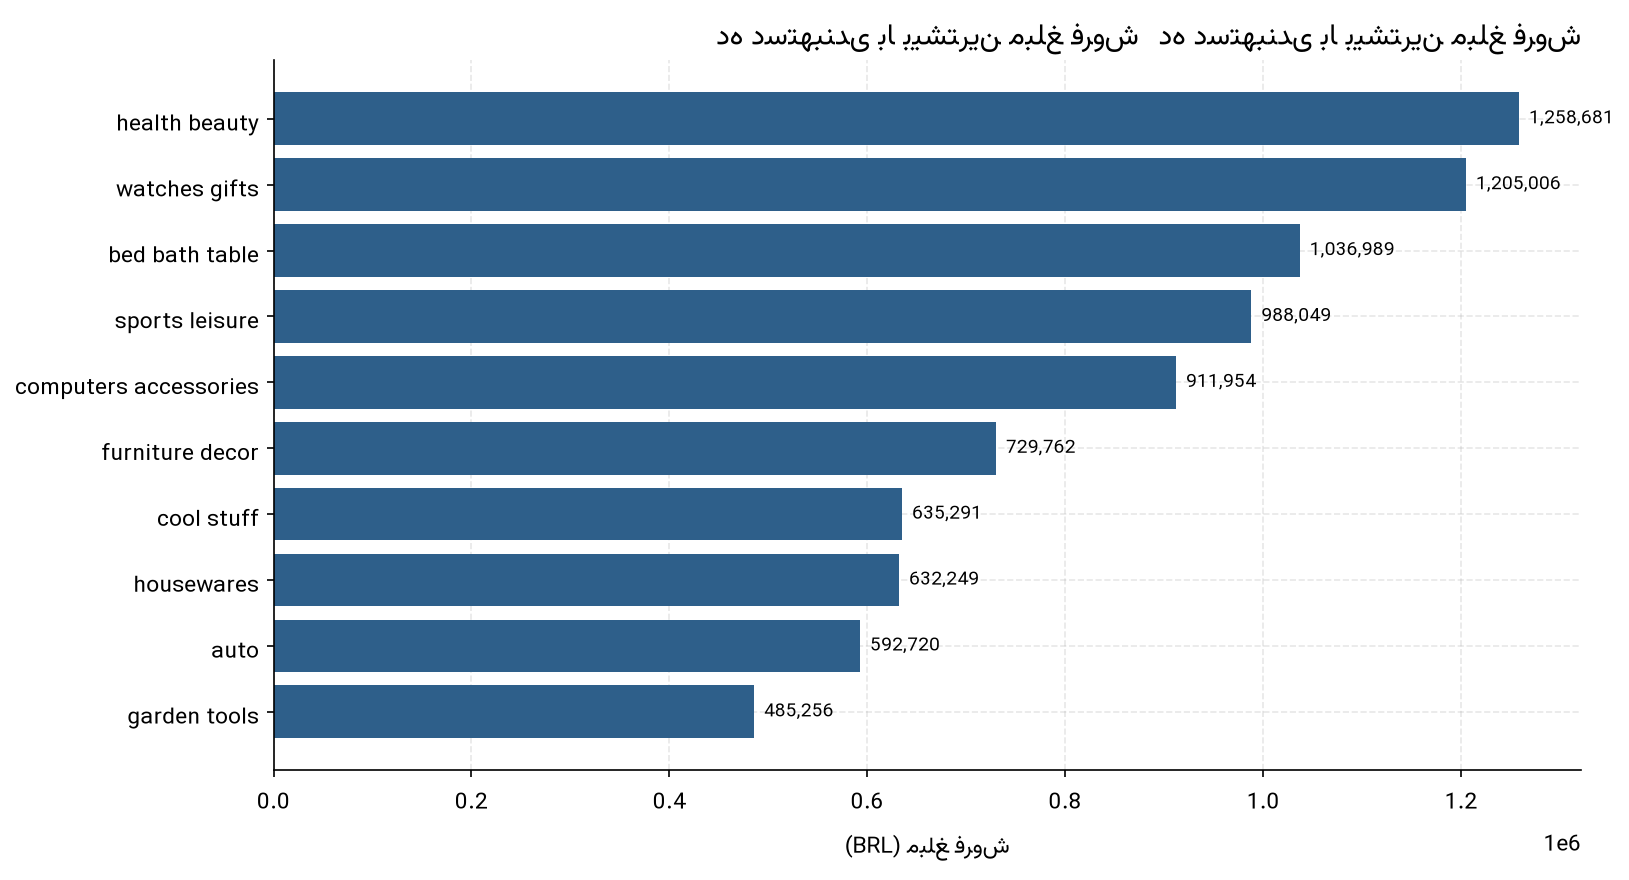

ده دستهبندی با بیشترین مبلغ فروش


In [8]:
display(Image(filename=str(FIGURES_DIR / "fig_09_top_categories_revenue.png"), width=920))
caption = FIGURES_DIR / "fig_09_top_categories_revenue.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

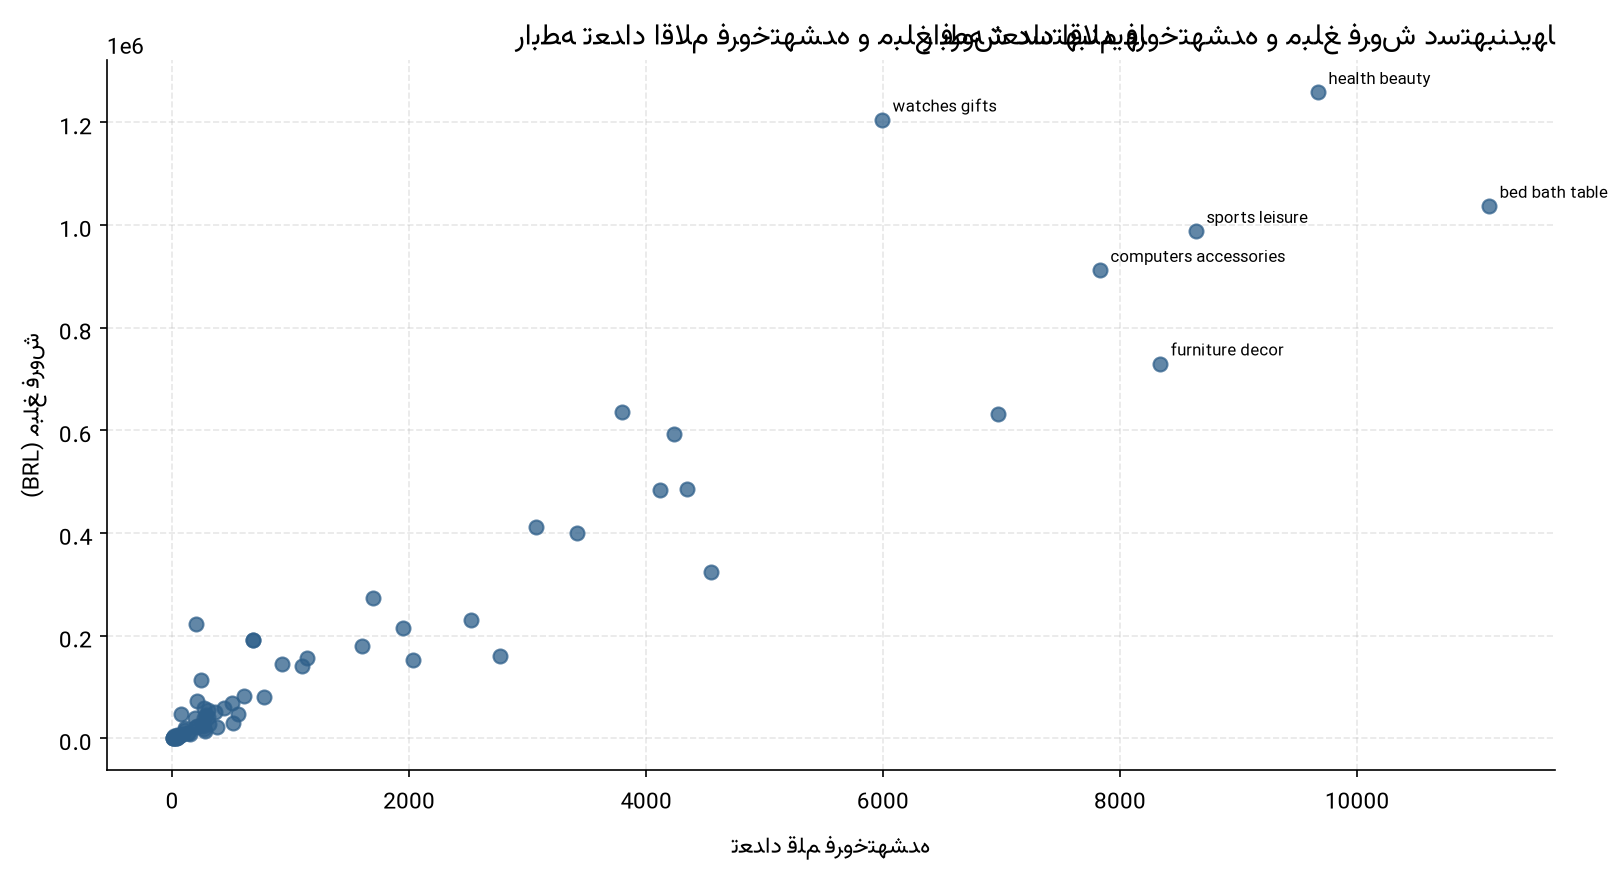

نمودار ۱۰ - دستهبندیهای دور از خط، عملکرد متفاوتی در حجم و مبلغ دارند


In [9]:
display(Image(filename=str(FIGURES_DIR / "fig_10_category_items_vs_revenue.png"), width=920))
caption = FIGURES_DIR / "fig_10_category_items_vs_revenue.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

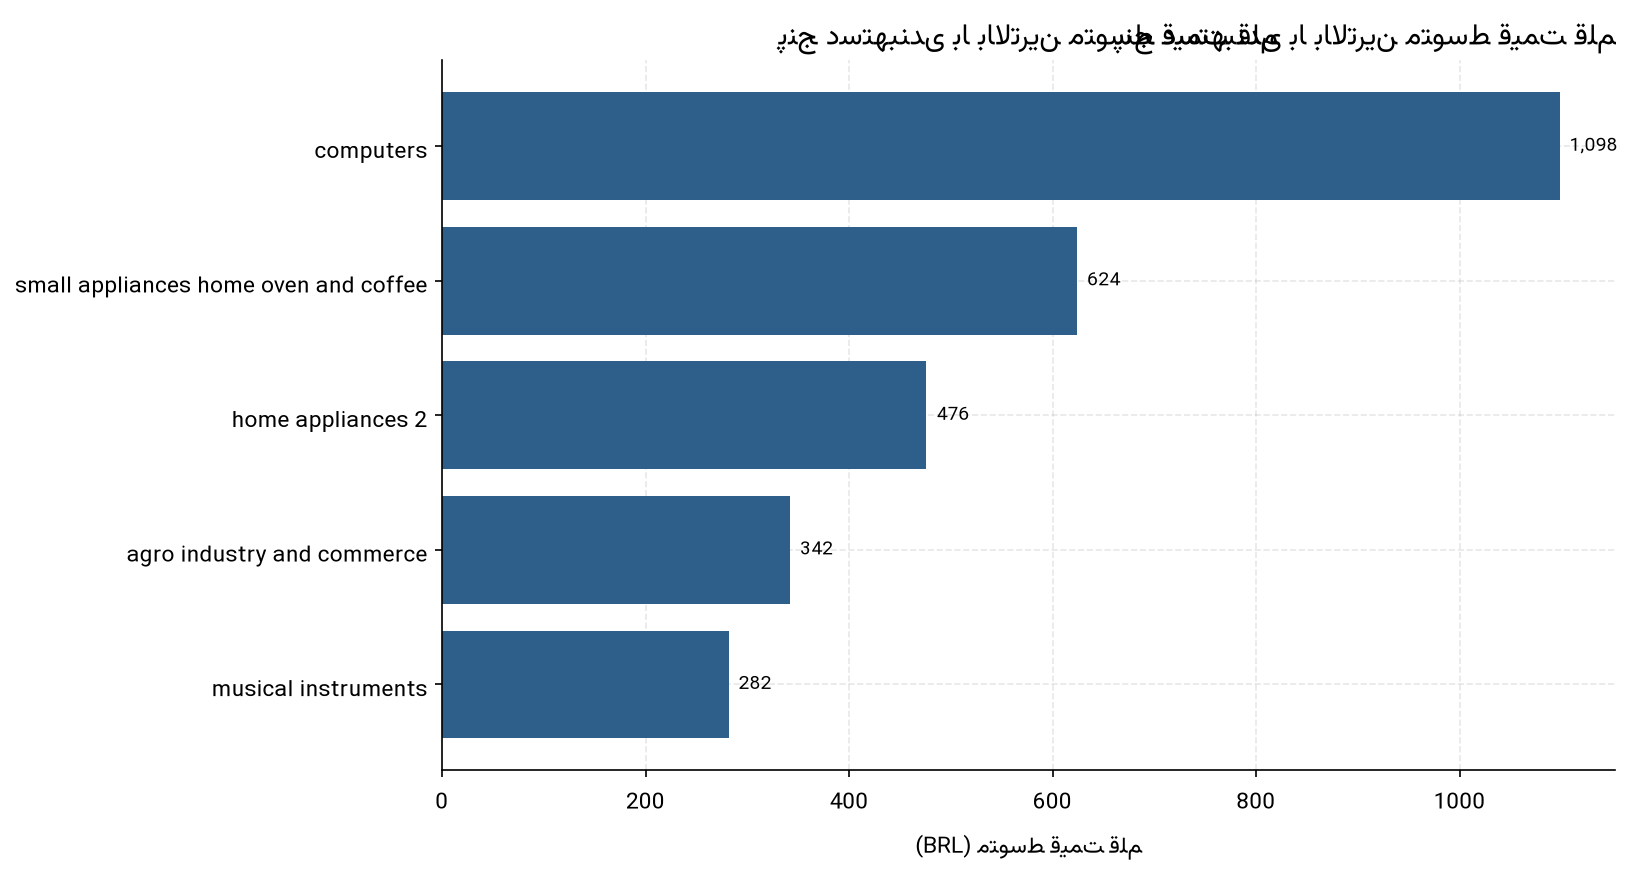

پنج دستهبندی با بالاترین متوسط قیمت قلم


In [10]:
display(Image(filename=str(FIGURES_DIR / "fig_11_top_categories_price.png"), width=920))
caption = FIGURES_DIR / "fig_11_top_categories_price.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

## ۸. یافته‌های واقعی

- ۷۳ دسته‌بندی محصول (بدون احتساب برچسب `unknown`) وجود دارد.
- `bed_bath_table` با ۱۱٬۱۱۵ قلم، رتبه اول حجم است اما در مبلغ فروش رتبه سوم را دارد.
- `health_beauty` با ۱٬۲۵۸٬۶۸۱ رئال رتبه اول مبلغ فروش است.
- `watches_gifts` با رتبه ۷ در حجم، رتبه ۲ در مبلغ فروش را دارد؛ فاصله ۵ رتبه‌ای نشان می‌دهد متوسط قیمت بالای آن (۲۰۱ رئال) جبران کمبود حجم را می‌کند.
- `computers` با متوسط قیمت ۱٬۰۹۸ رئال گران‌ترین دسته‌بندی است اما از نظر مبلغ فروش رتبه ۱۷ را دارد.
- پنج دسته‌بندی اول ۴۰.۲۷ درصد کل مبلغ فروش را تشکیل می‌دهند.

## ۹. تفسیر کسب‌وکاری

تصمیم‌گیری فقط بر پایه حجم فروش گمراه‌کننده است: `bed_bath_table` پرحجم‌ترین است اما ارزش کم‌تری به ازای هر قلم تولید می‌کند، در حالی که `watches_gifts` با حجم کم‌تر ارزش بیشتری می‌سازد. برای تیم فروش، ترکیب «حجم» و «ارزش» تعیین‌کننده اولویت است.

## ۱۰. محدودیت‌های تحلیل

مبلغ فروش با درآمد خالص یا سود یکسان نیست (هزینه ارسال، تخفیف و بازگشت کالا در آن لحاظ نشده است). ۶۱۰ محصول بدون دسته‌بندی در مبلغ کل باقی مانده‌اند اما در رتبه‌بندی‌ها کنار گذاشته شده‌اند.

## ۱۱. نتیجه‌گیری

عملکرد دسته‌بندی‌ها باید هم‌زمان بر پایه حجم و ارزش سنجیده شود؛ تمرکز درآمد در چند دسته‌بندی، هم فرصت و هم ریسک است.